In [1]:
import pandas as pd 
import numpy as np 
from sklearn.datasets import fetch_openml # Configuraciones de visualización de pandas 
pd.set_option('display.max_columns', None) 
pd.set_option('display.float_format', lambda x: '%.4f' % x) 
# Cargamos el dataset Ames Housing 
print("Descargando dataset...") 
ames = fetch_openml(name="house_prices", as_frame=True, parser="auto") 
df = ames.frame 
print(f"Dimensiones del dataset original: {df.shape}")

Descargando dataset...
Dimensiones del dataset original: (1460, 81)


# Descripción multivariante — Ames Housing

**Objetivo:** caracterizar la estructura conjunta del dataset (1460 ventas de viviendas en Ames, Iowa; 79 predictores + `SalePrice`) antes de cualquier modelado: tipos de variables, faltantes, distribución del target, dependencias entre predictores, relación predictor–target y estructura latente (PCA).

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid", context="notebook")
df = df.drop(columns="Id")
num_cols = df.select_dtypes("number").columns.drop("SalePrice")
cat_cols = df.select_dtypes(exclude="number").columns
print(f"Numéricas: {len(num_cols)} | Categóricas: {len(cat_cols)}")

Numéricas: 36 | Categóricas: 43


## 1. Tipos de variables

Las 36 numéricas no son todas continuas. Algunas son **ordinales codificadas como enteros** (`OverallQual`, `OverallCond`), otras son **conteos** (baños, habitaciones, autos en garage) y otras son **nominales disfrazadas** (`MSSubClass`). A su vez, varias categóricas son **ordinales en texto** (`ExterQual`, `KitchenQual`, `BsmtQual`… con escala Po < Fa < TA < Gd < Ex). Esto condiciona qué medida de asociación corresponde usar en cada caso.

In [3]:
n_unique = df[num_cols].nunique().sort_values()
print("Numéricas con pocos niveles (probablemente discretas/ordinales):")
print(n_unique[n_unique <= 15].to_string())

Numéricas con pocos niveles (probablemente discretas/ordinales):
BsmtHalfBath     3
HalfBath         3
Fireplaces       4
KitchenAbvGr     4
FullBath         4
BsmtFullBath     4
GarageCars       5
YrSold           5
PoolArea         8
BedroomAbvGr     8
OverallCond      9
OverallQual     10
TotRmsAbvGrd    12
MoSold          12
MSSubClass      15


## 1.b Mínimos, máximos y valores nulos

Tabla de resumen por variable numérica: rango (mín–máx), cantidad de nulos y cantidad de ceros. Los ceros importan porque en este dataset muchas veces equivalen a un faltante estructural: por ejemplo, `PoolArea = 0` significa que no hay piscina.

In [4]:
resumen_num = pd.DataFrame({
    "min": df[num_cols].min(),
    "max": df[num_cols].max(),
    "media": df[num_cols].mean(),
    "mediana": df[num_cols].median(),
    "nulos": df[num_cols].isna().sum(),
    "%_nulos": df[num_cols].isna().mean() * 100,
    "ceros": (df[num_cols] == 0).sum(),
    "%_ceros": (df[num_cols] == 0).mean() * 100,
})
sp = df["SalePrice"]
resumen_num.loc["SalePrice"] = [sp.min(), sp.max(), sp.mean(), sp.median(), sp.isna().sum(), 0, 0, 0]
resumen_num.sort_values("%_nulos", ascending=False)

,min,max,media,mediana,nulos,%_nulos,ceros,%_ceros
LotFrontage,21.0000,313.0000,70.0500,69.0000,259.0000,17.7397,0.0000,0.0000
GarageYrBlt,1900.0000,2010.0000,1978.5062,1980.0000,81.0000,5.5479,0.0000,0.0000
MasVnrArea,0.0000,1600.0000,103.6853,0.0000,8.0000,0.5479,861.0000,58.9726
OpenPorchSF,0.0000,547.0000,46.6603,25.0000,0.0000,0.0000,656.0000,44.9315
KitchenAbvGr,0.0000,3.0000,1.0466,1.0000,0.0000,0.0000,1.0000,0.0685
TotRmsAbvGrd,2.0000,14.0000,6.5178,6.0000,0.0000,0.0000,0.0000,0.0000
Fireplaces,0.0000,3.0000,0.6130,1.0000,0.0000,0.0000,690.0000,47.2603
GarageCars,0.0000,4.0000,1.7671,2.0000,0.0000,0.0000,81.0000,5.5479
GarageArea,0.0000,1418.0000,472.9801,480.0000,0.0000,0.0000,81.0000,5.5479
WoodDeckSF,0.0000,857.0000,94.2445,0.0000,0.0000,0.0000,761.0000,52.1233


In [5]:
# Fila donde se da el mínimo y el máximo de cada variable (para revisar extremos)
extremos = pd.DataFrame({
    "idx_min": df[num_cols].idxmin(),
    "idx_max": df[num_cols].idxmax(),
})
extremos.join(resumen_num[["min", "max"]])

,idx_min,idx_max,min,max
MSSubClass,1,9,20.0000,190.0000
LotFrontage,75,934,21.0000,313.0000
LotArea,956,313,1300.0000,215245.0000
OverallQual,375,58,1.0000,10.0000
OverallCond,375,185,1.0000,9.0000
YearBuilt,1349,378,1872.0000,2010.0000
YearRemodAdd,8,157,1950.0000,2010.0000
MasVnrArea,1,297,0.0000,1600.0000
BsmtFinSF1,8,1298,0.0000,5644.0000
BsmtFinSF2,0,322,0.0000,1474.0000


In [6]:
resumen_cat = pd.DataFrame({
    "niveles": df[cat_cols].nunique(),
    "moda": df[cat_cols].mode().iloc[0],
    "%_moda": df[cat_cols].apply(lambda s: s.value_counts(normalize=True).iloc[0] * 100),
    "nulos": df[cat_cols].isna().sum(),
    "%_nulos": df[cat_cols].isna().mean() * 100,
})
resumen_cat.sort_values("%_nulos", ascending=False)

,niveles,moda,%_moda,nulos,%_nulos
PoolQC,3,Gd,42.8571,1453,99.5205
MiscFeature,4,Shed,90.7407,1406,96.3014
Alley,2,Grvl,54.9451,1369,93.7671
Fence,4,MnPrv,55.8719,1179,80.7534
FireplaceQu,5,Gd,49.3506,690,47.2603
GarageType,6,Attchd,63.0892,81,5.5479
GarageCond,5,TA,96.1566,81,5.5479
GarageQual,5,TA,95.0689,81,5.5479
GarageFinish,3,Unf,43.8724,81,5.5479
BsmtFinType2,6,Unf,88.3263,38,2.6027


In [7]:
total_nulos = df.isna().sum().sum()
print(f"Celdas nulas: {total_nulos} de {df.size} ({total_nulos / df.size:.2%})")
print(f"Variables con al menos un nulo: {df.isna().any().sum()} de {df.shape[1]}")
print(f"Filas con al menos un nulo: {df.isna().any(axis=1).sum()} de {len(df)}")

# Chequeos de coherencia de rangos
print("\nIncoherencias:")
print(" YearRemodAdd < YearBuilt:", (df["YearRemodAdd"] < df["YearBuilt"]).sum())
print(" GarageYrBlt  < YearBuilt:", (df["GarageYrBlt"] < df["YearBuilt"]).sum())
print(" YrSold < YearBuilt:      ", (df["YrSold"] < df["YearBuilt"]).sum())
print(" GarageYrBlt > YrSold:    ", (df["GarageYrBlt"] > df["YrSold"]).sum())
print(" YearRemodAdd > YrSold:   ", (df["YearRemodAdd"] > df["YrSold"]).sum())

Celdas nulas: 6965 de 116800 (5.96%)
Variables con al menos un nulo: 19 de 80
Filas con al menos un nulo: 1460 de 1460

Incoherencias:
 YearRemodAdd < YearBuilt: 0
 GarageYrBlt  < YearBuilt: 9
 YrSold < YearBuilt:       0
 GarageYrBlt > YrSold:     0
 YearRemodAdd > YrSold:    1


### Hallazgos

**Nulos**
- Hay 6965 celdas nulas (6,0% del total), repartidas en 19 variables. **Todas las filas tienen al menos un nulo**, por la combinación de `PoolQC`, `MiscFeature`, `Alley` y `Fence`. Por eso un `dropna()` borraría el dataset entero.
- Casi todos los nulos son **estructurales** y significan que no hay ese elemento: piscina, callejón, cerco, chimenea (`FireplaceQu`, que coincide con las 690 casas con `Fireplaces = 0`), garage (81, que coincide con `GarageCars = 0`) o sótano (37, que coincide con `TotalBsmtSF = 0`).
- Los **nulos reales** son pocos:
  - `LotFrontage`: 259 casos (17,7%).
  - `MasVnrType`/`MasVnrArea`: 8 casos, los mismos en las dos variables.
  - `Electrical`: 1 caso.
  - `BsmtExposure` y `BsmtFinType2` tienen 38 nulos, no 37 como el resto de las `Bsmt*`. Hay una casa con sótano y exposición faltante (fila 948) y otra con `BsmtFinSF2 = 479` pero sin tipo (fila 332).

**Mínimos y máximos sospechosos**
- `YearRemodAdd` tiene mínimo 1950 en 178 casas, aunque 318 se construyeron antes de ese año. 1950 es un **valor techo de codificación**: significa "sin remodelación registrada", no una fecha real.
- `GarageYrBlt` tiene 81 nulos, que corresponden a las casas sin garage. Imputarlo con 0 o con la mediana crea años sin sentido; es mejor derivar `GarageAge` o usar `YearBuilt`.
- Hay **ceros que deberían revisarse**: 6 casas con `BedroomAbvGr = 0`, 9 con `FullBath = 0` y 1 con `KitchenAbvGr = 0`. Pueden ser válidos (por ejemplo, habitaciones solo en el sótano) o errores de carga.
- **Máximos extremos:**
  - `LotArea` = 215.245 ft² (fila 313), unas 20 veces la mediana.
  - `MiscVal` = 15.500.
  - `BsmtFinSF1` = 5644, `TotalBsmtSF` = 6110 y `GrLivArea` = 5642, todos en la **misma fila 1298**, que es el outlier multivariado de la sección 5.
- Las variables con más de 85% de ceros (`PoolArea`, `3SsnPorch`, `LowQualFinSF`, `MiscVal`, `BsmtHalfBath`, `ScreenPorch`, `BsmtFinSF2`, `EnclosedPorch`) son prácticamente indicadores binarios disfrazados de continuas.

**Coherencia entre variables**
- En 9 casas, `GarageYrBlt` es anterior a `YearBuilt`, por 1 a 10 años. Probablemente sea un error de registro (o el garage es anterior a una reconstrucción de la casa); no es grave.
- En 1 casa (fila 523), `YearRemodAdd` (2008) es posterior a `YrSold` (2007). Es una venta `New` de una casa en construcción, coherente con su `SaleCondition = Partial`.
- `MasVnrType = 'None'` está codificado como una categoría y no como NaN. Además, hay 5 casas con `MasVnrArea > 0` y tipo 'None', y 2 con área 0 y tipo distinto de 'None': son inconsistencias internas.


## 2. Valores faltantes

Hay que distinguir dos tipos. Los **faltantes estructurales** significan que la vivienda no tiene ese atributo: `PoolQC` NA = sin piscina, `Alley` NA = sin callejón, `Garage*` NA = sin garage. Los **faltantes reales** son datos que deberían existir y no están, como `LotFrontage`. Los primeros no se imputan, se recodifican como "None". Que todas las `Garage*` falten exactamente en el mismo 5,5% de los casos (lo mismo pasa con las `Bsmt*`) confirma que el faltante es estructural.

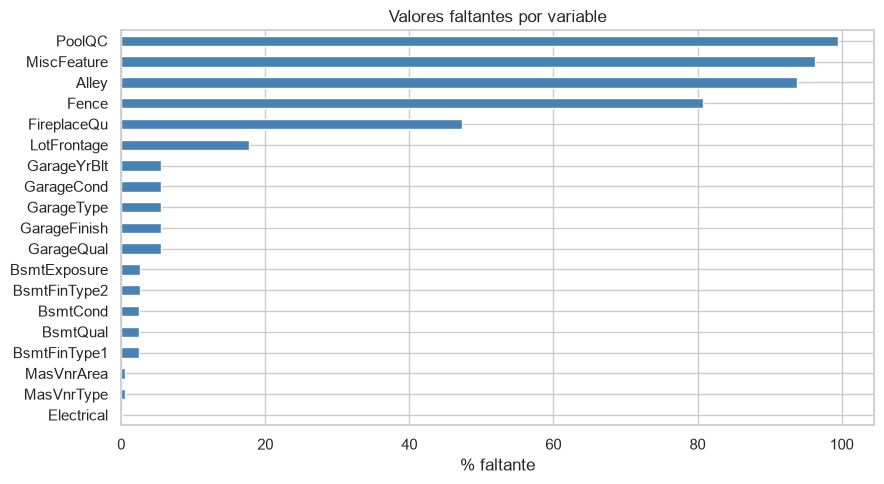

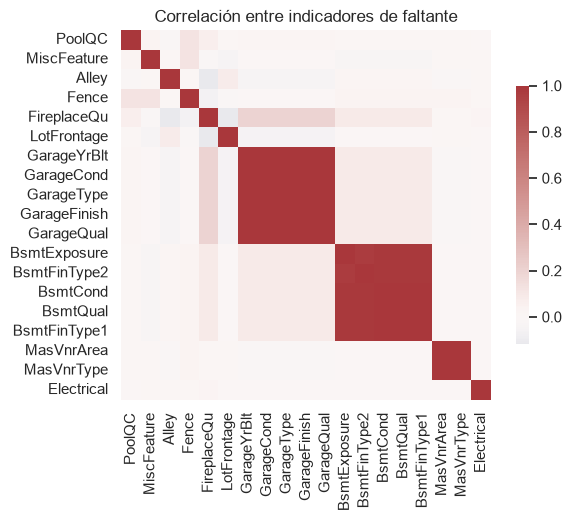

In [8]:
na = df.isna().mean().mul(100).sort_values(ascending=False)
na = na[na > 0]
fig, ax = plt.subplots(figsize=(9, 5))
na.plot.barh(ax=ax, color="steelblue").invert_yaxis()
ax.set_xlabel("% faltante"); ax.set_title("Valores faltantes por variable")
plt.tight_layout(); plt.show()

# patrón conjunto: ¿faltan juntas las variables del mismo bloque?
miss = df[na.index].isna()
sns.heatmap(miss.corr(), cmap="vlag", center=0, square=True, cbar_kws={"shrink": .7})
plt.title("Correlación entre indicadores de faltante"); plt.show()

## 3. Variable objetivo: `SalePrice`

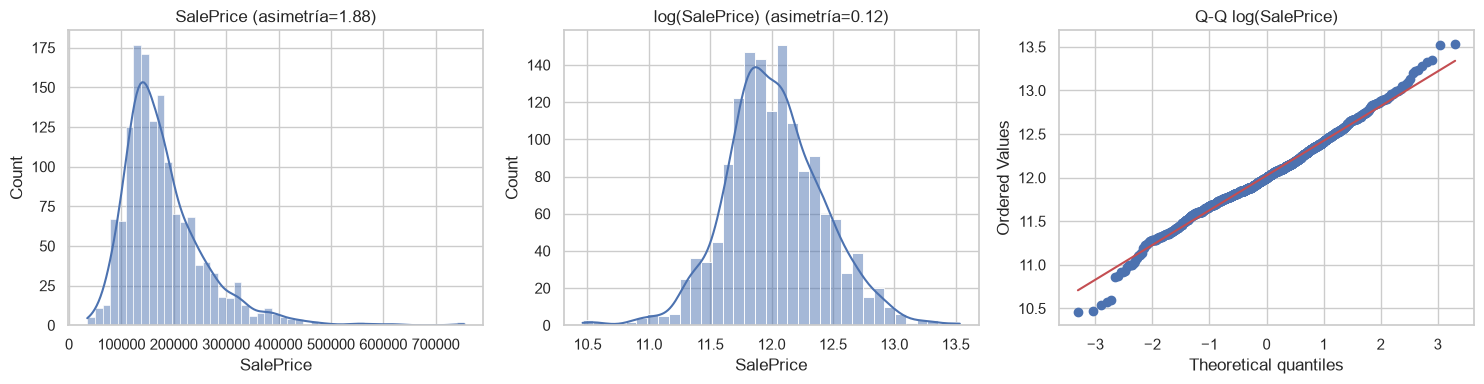

count     1460.0000
mean    180921.1959
std      79442.5029
min      34900.0000
25%     129975.0000
50%     163000.0000
75%     214000.0000
max     755000.0000
Name: SalePrice, dtype: float64

In [9]:
y = df["SalePrice"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(y, kde=True, ax=axes[0]); axes[0].set_title(f"SalePrice (asimetría={y.skew():.2f})")
sns.histplot(np.log(y), kde=True, ax=axes[1]); axes[1].set_title(f"log(SalePrice) (asimetría={np.log(y).skew():.2f})")
stats.probplot(np.log(y), plot=axes[2]); axes[2].set_title("Q-Q log(SalePrice)")
plt.tight_layout(); plt.show()
y.describe()

El precio tiene asimetría positiva marcada (≈1,88) y cola derecha larga. Con el logaritmo, la distribución queda casi simétrica (≈0,12). De acá en adelante trabajo con `log(SalePrice)`, que además es la escala natural para pensar en efectos multiplicativos (un X% más caro).

## 4. Asociación entre variables numéricas

Uso **Spearman**: no exige linealidad, es robusto a la asimetría y tolera variables ordinales y de conteo.

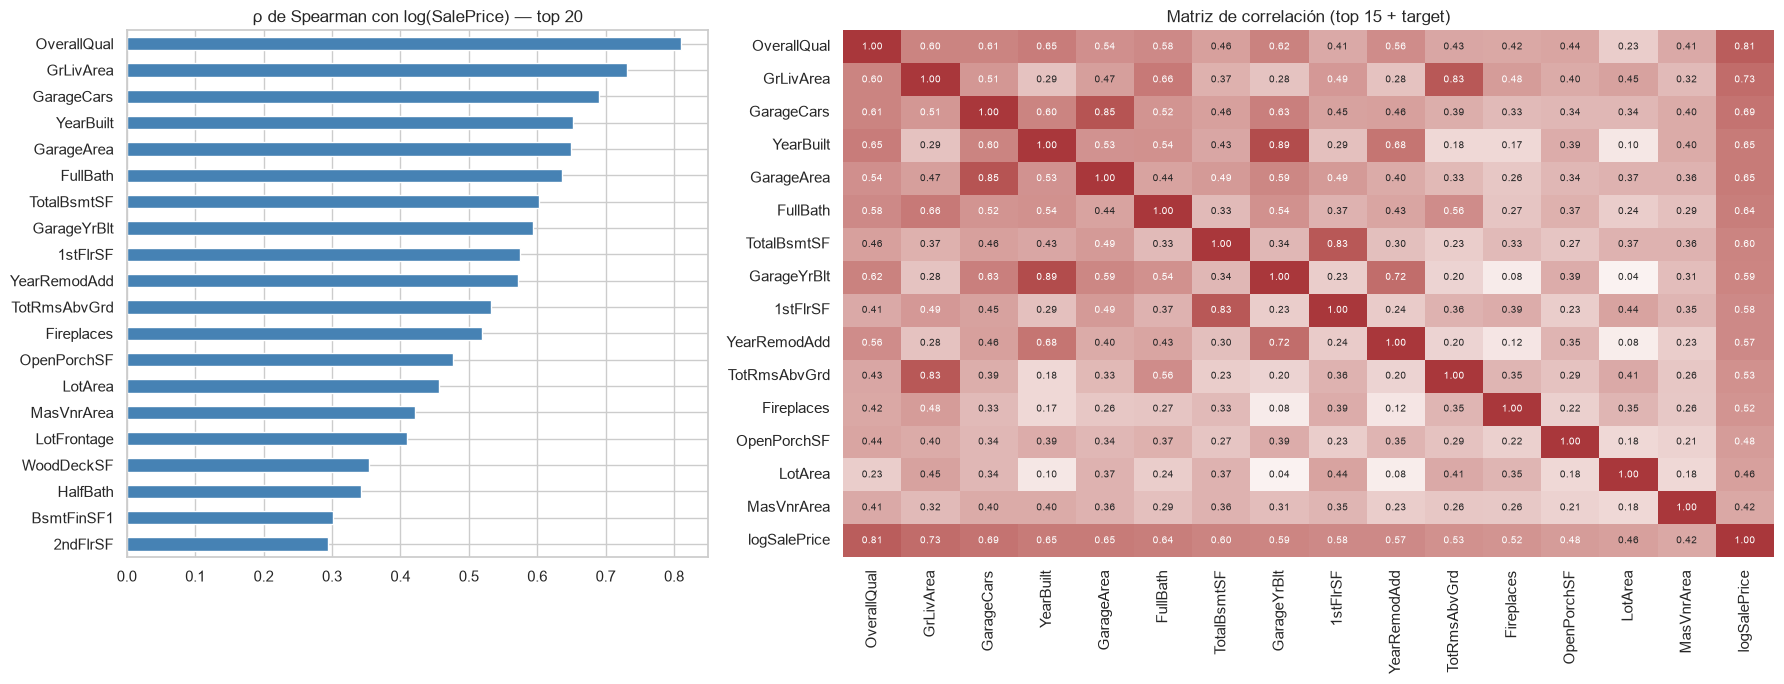

In [10]:
df["logSalePrice"] = np.log(df["SalePrice"])
corr = df[list(num_cols) + ["logSalePrice"]].corr(method="spearman")

target_corr = corr["logSalePrice"].drop("logSalePrice").sort_values(key=abs, ascending=False)
top = target_corr.head(15).index.tolist()

fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={"width_ratios": [1, 1.6]})
target_corr.head(20).iloc[::-1].plot.barh(ax=axes[0], color=np.where(target_corr.head(20).iloc[::-1] > 0, "steelblue", "indianred"))
axes[0].set_title("ρ de Spearman con log(SalePrice) — top 20")
sns.heatmap(corr.loc[top + ["logSalePrice"], top + ["logSalePrice"]], annot=True, fmt=".2f",
            cmap="vlag", center=0, ax=axes[1], annot_kws={"size": 7}, cbar=False)
axes[1].set_title("Matriz de correlación (top 15 + target)")
plt.tight_layout(); plt.show()

Las variables que más se asocian con el precio cubren tres dimensiones: **calidad** (`OverallQual`, ρ≈0,81), **tamaño** (`GrLivArea` 0,73, `GarageCars` 0,69, `TotalBsmtSF` 0,60) y **antigüedad** (`YearBuilt` 0,65, `YearRemodAdd` 0,57). Las pocas asociaciones negativas son débiles (`EnclosedPorch` −0,22, `KitchenAbvGr` −0,17). `OverallCond` también da negativa (−0,13), algo contraintuitivo: se explica porque las casas viejas tienden a tener una condición "promedio-buena" pero valen menos. Es un primer indicio de confusión por la edad.

### Multicolinealidad

Pares de predictores con |ρ| > 0,7: miden prácticamente lo mismo.

In [11]:
c = corr.drop(index="logSalePrice", columns="logSalePrice").abs()
pairs = (c.where(np.triu(np.ones(c.shape, dtype=bool), 1)).stack()
           .sort_values(ascending=False).rename("|ρ|"))
pairs[pairs > 0.7].to_frame()

,,|ρ|
YearBuilt,GarageYrBlt,0.8905
GarageCars,GarageArea,0.8533
TotalBsmtSF,1stFlrSF,0.8293
GrLivArea,TotRmsAbvGrd,0.8279
YearRemodAdd,GarageYrBlt,0.7224


Hay redundancias claras, todas con una explicación física:
- `GarageCars` ↔ `GarageArea`: los dos miden el tamaño del garage.
- `YearBuilt` ↔ `GarageYrBlt`: el garage casi siempre se construye junto con la casa.
- `TotalBsmtSF` ↔ `1stFlrSF`: el sótano ocupa la huella de la planta baja.
- `GrLivArea` ↔ `TotRmsAbvGrd`: más superficie implica más ambientes.

En un modelo lineal conviene quedarse con una variable de cada par o combinarlas (por ejemplo, `TotalSF = TotalBsmtSF + GrLivArea`). Si no, los coeficientes quedan inestables y no se pueden interpretar.

## 5. Relaciones bivariadas con el target y outliers multivariados

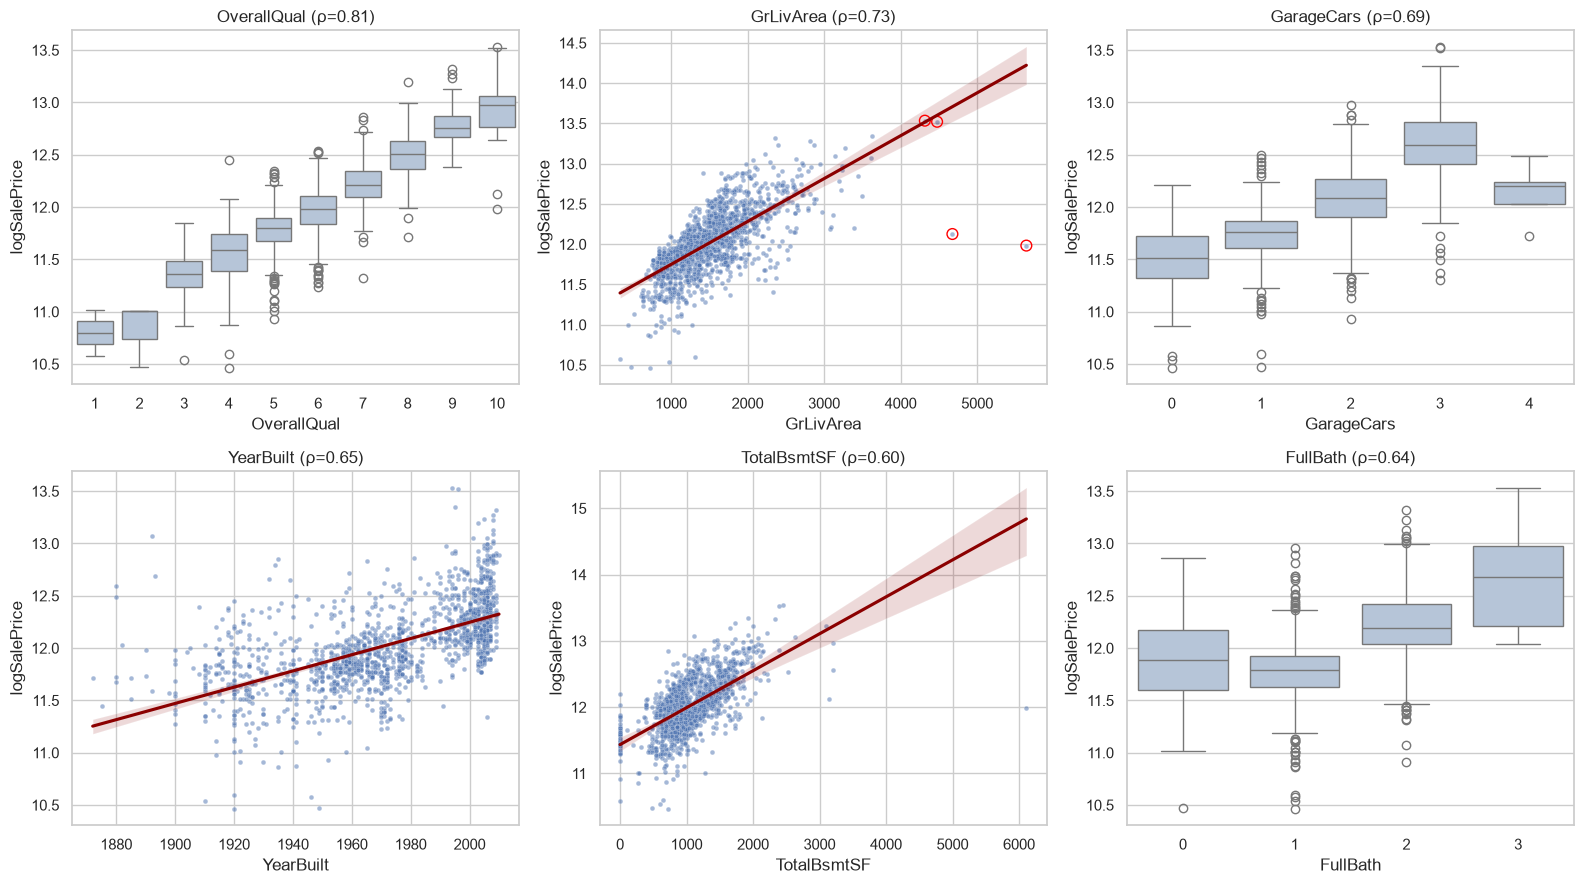

,GrLivArea,SalePrice,SaleCondition,Neighborhood
523,4676,184750,Partial,Edwards
691,4316,755000,Normal,NoRidge
1182,4476,745000,Abnorml,NoRidge
1298,5642,160000,Partial,Edwards


In [12]:
cols = ["OverallQual", "GrLivArea", "GarageCars", "YearBuilt", "TotalBsmtSF", "FullBath"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, cols):
    if df[col].nunique() <= 12:
        sns.boxplot(x=df[col], y=df["logSalePrice"], ax=ax, color="lightsteelblue")
    else:
        sns.scatterplot(x=df[col], y=df["logSalePrice"], ax=ax, s=12, alpha=.5)
        sns.regplot(x=df[col], y=df["logSalePrice"], ax=ax, scatter=False, color="darkred")
    ax.set_title(f"{col} (ρ={corr.loc[col, 'logSalePrice']:.2f})")
# marcar outliers conocidos
out = df["GrLivArea"] > 4000
axes[0, 1].scatter(df.loc[out, "GrLivArea"], df.loc[out, "logSalePrice"], s=60, facecolors="none", edgecolors="red")
plt.tight_layout(); plt.show()
df.loc[out, ["GrLivArea", "SalePrice", "SaleCondition", "Neighborhood"]]

Hay cuatro viviendas con `GrLivArea` > 4000 ft². Dos de ellas (índices 523 y 1298) son **outliers multivariados**: muy grandes y baratas, ventas `Partial` en Edwards. Ninguna de las dos variables es extrema por separado en precio; lo anómalo es la combinación. Son los casos que el propio autor del dataset (De Cock, 2011) recomienda excluir, y pueden distorsionar mucho un modelo lineal.

## 6. Variables categóricas vs. target

Para comparar las categóricas entre sí uso la **razón de correlación η²**: la proporción de la varianza de `log(SalePrice)` que explica la variable. Es el análogo de R² en un ANOVA de una vía.

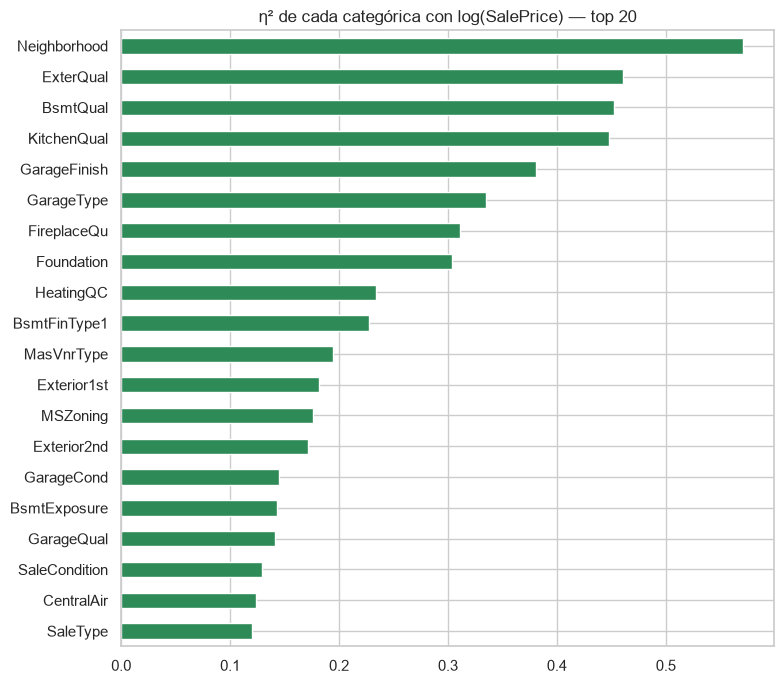

In [13]:
def eta2(cat, y):
    d = pd.DataFrame({"c": cat.astype(str).fillna("NA"), "y": y})
    ss_between = d.groupby("c")["y"].apply(lambda g: len(g) * (g.mean() - d["y"].mean())**2).sum()
    return ss_between / ((d["y"] - d["y"].mean())**2).sum()

eta = pd.Series({c: eta2(df[c], df["logSalePrice"]) for c in cat_cols}).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 7))
eta.head(20).iloc[::-1].plot.barh(ax=ax, color="seagreen")
ax.set_title("η² de cada categórica con log(SalePrice) — top 20"); plt.tight_layout(); plt.show()

`Neighborhood` es la categórica con más información: sola explica ≈57% de la varianza de log(precio). Le siguen las de calidad ordinal: `ExterQual` (0,46), `KitchenQual` (0,45) y `BsmtQual` (0,41). Estas tres repiten mucho de lo que ya captura `OverallQual`, es decir, son otra cara del mismo factor "calidad". `Foundation` (0,30) funciona más bien como proxy de época constructiva: PConc = moderna, CBlock/BrkTil = vieja.

Una advertencia: η² aumenta con la cantidad de niveles. `Neighborhood` tiene 25, así que parte de su ventaja es mecánica. Aun así, el gradiente entre barrios es enorme: la mediana va de ~88k (MeadowV) a ~315k (NridgHt).

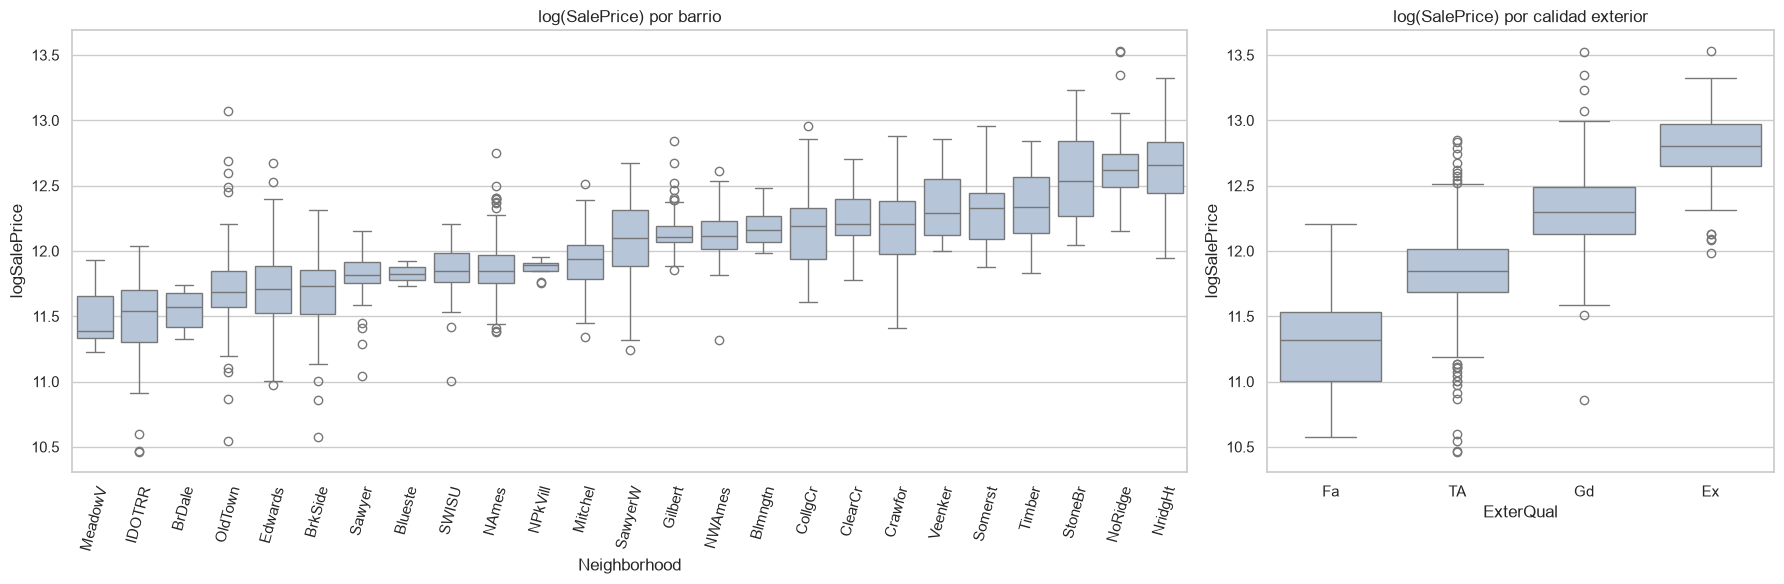

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [2.2, 1]})
order = df.groupby("Neighborhood", observed=True)["logSalePrice"].median().sort_values().index
sns.boxplot(data=df, x="Neighborhood", y="logSalePrice", order=order, ax=axes[0], color="lightsteelblue")
axes[0].tick_params(axis="x", rotation=75); axes[0].set_title("log(SalePrice) por barrio")
sns.boxplot(data=df, x="ExterQual", y="logSalePrice", order=["Fa", "TA", "Gd", "Ex"], ax=axes[1], color="lightsteelblue")
axes[1].set_title("log(SalePrice) por calidad exterior")
plt.tight_layout(); plt.show()

### Interacción: calidad × superficie × barrio

La pregunta es si la relación superficie–precio cambia según el nivel de calidad.

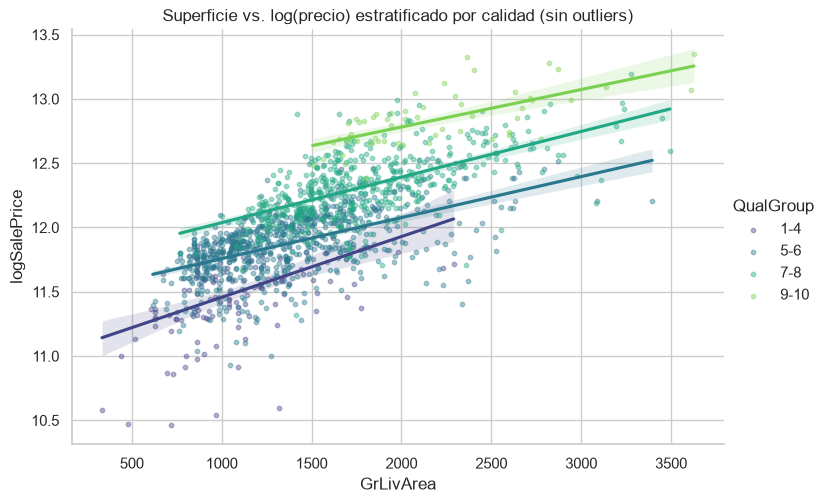

In [15]:
df["QualGroup"] = pd.cut(df["OverallQual"], [0, 4, 6, 8, 10], labels=["1-4", "5-6", "7-8", "9-10"])
g = sns.lmplot(data=df[~out], x="GrLivArea", y="logSalePrice", hue="QualGroup",
               scatter_kws={"s": 10, "alpha": .4}, height=5, aspect=1.5, palette="viridis")
g.ax.set_title("Superficie vs. log(precio) estratificado por calidad (sin outliers)"); plt.show()

Las rectas son aproximadamente paralelas y están desplazadas hacia arriba según la calidad. En escala log, eso significa que **calidad y superficie actúan de forma mayormente aditiva**: cada nivel de calidad multiplica el precio por un factor parecido sin importar el tamaño. También se ve la **confusión** entre las dos: las casas de calidad alta tienden a ser grandes, así que la correlación marginal de `GrLivArea` sobrestima su efecto propio.

## 7. Estructura latente: PCA

PCA sobre los predictores numéricos estandarizados, con los faltantes imputados por la mediana. Es exploratorio: sirve para ver cuántas dimensiones independientes hay de verdad entre las 36 variables.

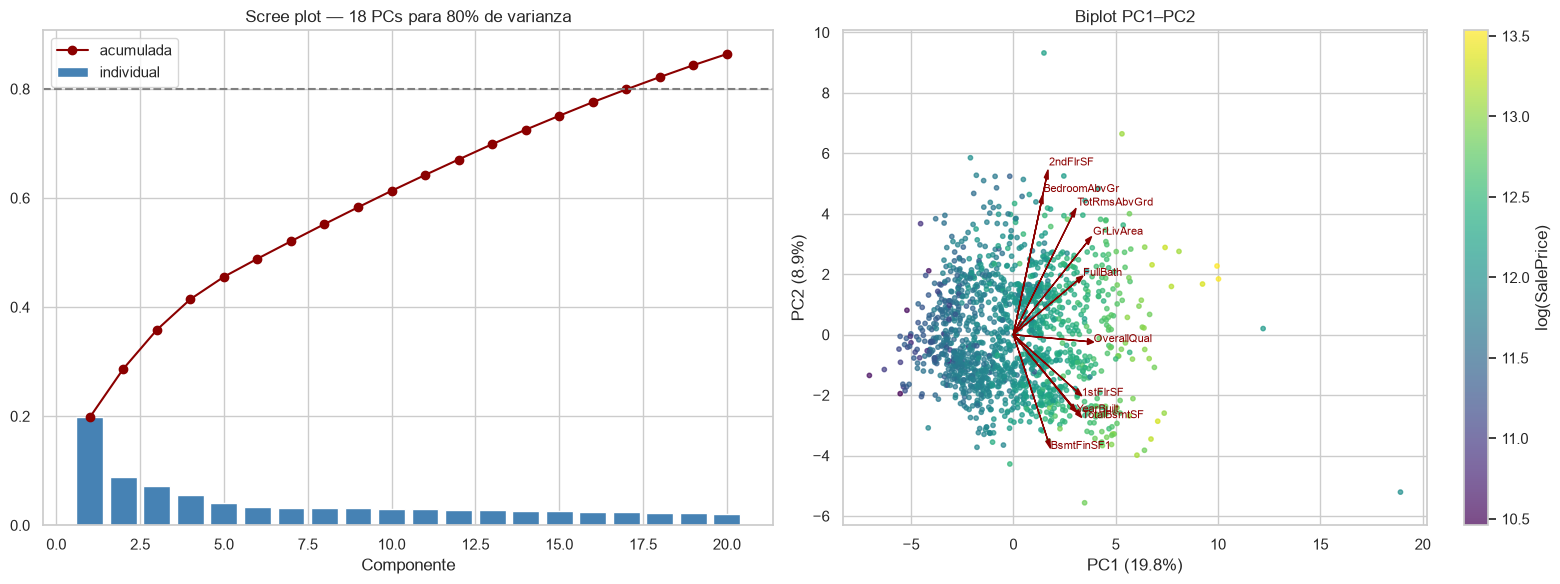

PC1 {'OverallQual': 0.3, 'GrLivArea': 0.3, 'GarageCars': 0.28, 'GarageArea': 0.28, 'FullBath': 0.26, 'TotalBsmtSF': 0.26}
PC2 {'2ndFlrSF': 0.43, 'BedroomAbvGr': 0.36, 'TotRmsAbvGrd': 0.33, 'BsmtFinSF1': -0.29, 'BsmtFullBath': -0.29, 'GrLivArea': 0.25}
PC3 {'GarageYrBlt': 0.36, 'YearBuilt': 0.32, 'LotArea': -0.28, 'LotFrontage': -0.27, 'YearRemodAdd': 0.27, '1stFlrSF': -0.26}
ρ(PC1, log precio) = 0.914


In [16]:
X = df[num_cols].fillna(df[num_cols].median())
Z = StandardScaler().fit_transform(X)
pca = PCA().fit(Z)
ev = pca.explained_variance_ratio_
scores = pca.transform(Z)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].bar(range(1, 21), ev[:20], color="steelblue", label="individual")
axes[0].plot(range(1, 21), ev.cumsum()[:20], "o-", color="darkred", label="acumulada")
axes[0].axhline(.8, ls="--", c="gray"); axes[0].set_xlabel("Componente"); axes[0].legend()
axes[0].set_title(f"Scree plot — {np.argmax(ev.cumsum() >= .8) + 1} PCs para 80% de varianza")

sc = axes[1].scatter(scores[:, 0], scores[:, 1], c=df["logSalePrice"], cmap="viridis", s=10, alpha=.7)
plt.colorbar(sc, ax=axes[1], label="log(SalePrice)")
load = pd.DataFrame(pca.components_[:2].T, index=num_cols, columns=["PC1", "PC2"])
for v in load.pow(2).sum(axis=1).nlargest(10).index:
    axes[1].arrow(0, 0, load.loc[v, "PC1"] * 12, load.loc[v, "PC2"] * 12, color="darkred", head_width=.2)
    axes[1].text(load.loc[v, "PC1"] * 13, load.loc[v, "PC2"] * 13, v, fontsize=8, color="darkred")
axes[1].set_xlabel(f"PC1 ({ev[0]:.1%})"); axes[1].set_ylabel(f"PC2 ({ev[1]:.1%})"); axes[1].set_title("Biplot PC1–PC2")
plt.tight_layout(); plt.show()

loadings = pd.DataFrame(pca.components_[:3].T, index=num_cols, columns=["PC1", "PC2", "PC3"])
for pc in loadings:
    print(pc, loadings[pc].sort_values(key=abs, ascending=False).head(6).round(2).to_dict())
print("ρ(PC1, log precio) =", round(stats.spearmanr(scores[:, 0], df["logSalePrice"])[0], 3))

- **PC1 (≈20%) = "tamaño + calidad + modernidad".** Todos los loadings importantes tienen el mismo signo (`OverallQual`, `GrLivArea`, `GarageCars`, `TotalBsmtSF`, `FullBath`). Es un factor general de "casa grande, buena y nueva". Aunque se construyó **sin mirar el precio**, PC1 tiene ρ≈0,91 con log(SalePrice): el principal eje de variación de las viviendas es justamente el que determina el precio.
- **PC2 (≈9%) = distribución vertical.** Contrapone las casas de dos plantas (`2ndFlrSF`, `BedroomAbvGr`, `TotRmsAbvGrd`) a las de una planta con sótano terminado (`BsmtFinSF1`, `BsmtFullBath`). Es un eje de *tipo* de vivienda, casi ortogonal al precio, como se ve en el biplot: el color varía de izquierda a derecha, no de arriba abajo.
- **PC3 (≈7%) = antigüedad vs. lote.** Las casas nuevas tienen lotes más chicos (`YearBuilt` +, `LotArea`/`LotFrontage` −), algo típico de los loteos suburbanos recientes.
- Hacen falta 18 componentes para llegar al 80% de la varianza. Fuera de las primeras 3–4, la varianza está muy repartida: hay muchas variables casi independientes y poco informativas (porches, `MiscVal`, `PoolArea`, `3SsnPorch`) que aportan ruido. Los dos puntos aislados a la derecha del biplot son los outliers de `GrLivArea` > 4000.

## 8. Conclusiones

1. **Estructura dominante.** El dataset está organizado alrededor de un factor latente "calidad–tamaño–modernidad" (PC1), que por sí solo ordena las viviendas por precio (ρ≈0,91). A eso se suma un fuerte efecto de **ubicación** (`Neighborhood`, η²≈0,57) que en parte es independiente.
2. **Target.** `SalePrice` tiene asimetría positiva (1,88). Conviene modelar `log(SalePrice)`, que es casi normal y vuelve aditivos los efectos de calidad y superficie.
3. **Redundancia.** Hay al menos cinco pares con |ρ|>0,7 y una familia entera de variables de calidad (`OverallQual`, `ExterQual`, `KitchenQual`, `BsmtQual`) que miden el mismo constructo. Para modelos lineales: selección, combinación (`TotalSF`, `TotalBath`, `Age = YrSold − YearBuilt`) o regularización (Ridge/Lasso). Los modelos de árboles son menos sensibles a esto.
4. **Faltantes.** Casi todos son estructurales (no tiene piscina, garage, sótano, etc.) y se recodifican como "None" o 0. Solo `LotFrontage` (17,7%) es un faltante real; tiene sentido imputarlo por barrio.
5. **Outliers.** Dos ventas `Partial` en Edwards, de más de 4500 ft² y precio bajo, son anómalas en lo multivariado y conviene excluirlas o tratarlas aparte.
6. **Codificación.** Las categóricas de calidad deberían codificarse **ordinalmente** (Po=1 … Ex=5), no con one-hot. `MSSubClass` debería pasar a nominal.
7. **Confusión.** Las asociaciones marginales están confundidas, sobre todo por la antigüedad (ejemplo: `OverallCond` negativa). Hay que interpretar los efectos de forma condicional, no marginal.